# iNaturalist genus × marine realm presence

For every genus in `configs/class_to_concepts.csv`:

1. resolve the genus to an iNaturalist taxon (homonyms disambiguated using the CSV's kingdom/phylum),
2. download **all research-grade observations** (iNat API v2, ~1 req/s, cached per genus in `inat/data/obs/`),
3. sanity-check a few genera on a world map,
4. assign each observation to a **MEOW realm** (Spalding et al. 2007, 12 realms) — point-in-polygon on the
   MEOW "NoCoast" layer, then snapping to the nearest ecoregion within `SNAP_KM` for coastal/near-shore points,
5. build the **N × M genus × realm matrix** (True if ≥ `MIN_OBS` observations), plus the raw count matrix
   and province/ecoregion counts so thresholds or region levels can be changed without re-downloading.

All network steps are cached; re-running the notebook is cheap. Delete a file in `inat/data/` to refresh it.

In [1]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from pyproj import Geod
from shapely.ops import nearest_points
from tqdm.auto import tqdm

ROOT = Path.cwd() if (Path.cwd() / "configs").exists() else Path.cwd().parent
INAT = ROOT / "inat"
DATA, OBS_DIR, OUT = INAT / "data", INAT / "data" / "obs", INAT / "outputs"
for p in (DATA, OBS_DIR, OUT):
    p.mkdir(parents=True, exist_ok=True)

CLASS2CONCEPTS = ROOT / "configs" / "class_to_concepts.csv"
MEOW_SHP = DATA / "meow" / "WCMC-036-MEOW-PPOW-2007-2012-NoCoast.shp"

SNAP_KM = 50      # snap points outside MEOW polygons to nearest ecoregion if within this distance
MIN_OBS = 1       # presence threshold (counts are saved too, so this can be changed later)

API = "https://api.inaturalist.org"
SESSION = requests.Session()
SESSION.headers["User-Agent"] = "mermaidseg-inat-genus-regions/0.1"

# palette (dataviz reference palette, categorical slots in fixed order)
C_BLUE, C_ORANGE, C_AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"

## 1. iNat API helper (rate-limited to ≤ 1 request/second, with retries)

In [2]:
_last_call = [0.0]

def inat_get(path, **params):
    for attempt in range(7):
        wait = 1.0 - (time.time() - _last_call[0])
        if wait > 0:
            time.sleep(wait)
        _last_call[0] = time.time()
        try:
            r = SESSION.get(API + path, params=params, timeout=90)
            if r.status_code == 200:
                return r.json()
            if r.status_code in (429, 500, 502, 503, 504):
                time.sleep(5 * 2 ** attempt)
                continue
            r.raise_for_status()
        except requests.RequestException as e:
            print("retry", attempt, e)
            time.sleep(5 * 2 ** attempt)
    raise RuntimeError(f"iNat request failed: {path} {params}")

## 2. Genera from `class_to_concepts.csv` → iNat taxa

Each CSV genus has a single kingdom/phylum. iNat genus candidates with an exact name match are scored by
phylum match > kingdom match > active status. `turbinaria_algae` / `turbinaria_coral` both search for *Turbinaria*
and get separated by phylum (Ochrophyta vs Cnidaria). Inactive iNat genera are replaced by their current synonym.

In [3]:
c2c = pd.read_csv(CLASS2CONCEPTS)
genera = (c2c[~c2c.genus.isin(["none", "not_given"]) & c2c.genus.notna()]
          .groupby("genus")[["kingdom", "phylum", "order", "family"]].first().reset_index())
print(len(genera), "genera")
genera.phylum.value_counts()

366 genera


phylum
cnidaria             196
rhodophyta            42
porifera              32
ochrophyta            23
chlorophyta           20
echinodermata         14
tracheophyta          12
chordata               8
mollusca               8
arthropoda             3
bryozoa                3
cyanobacteriota        2
prasinodermophyta      1
annelida               1
ascomycota             1
Name: count, dtype: int64

In [4]:
PHYLUM_ALIAS = {"cyanobacteriota": {"cyanobacteria", "cyanobacteriota"},
                "prasinodermophyta": {"prasinodermophyta", "chlorophyta"}}
KINGDOM_ALIAS = {"bacillati": {"bacteria"}}

def _anc(t, rank):
    for a in t.get("ancestors", []):
        if a["rank"] == rank:
            return a["name"].lower()
    return None

def resolve_genus(name, kingdom, phylum):
    q = name.split("_")[0]
    res = inat_get("/v1/taxa", q=q, rank="genus", per_page=30, is_active="any")["results"]
    cands = [t for t in res if t["name"].lower() == q]
    if not cands:
        return dict(genus=name, status="not_found")
    full = inat_get("/v1/taxa/" + ",".join(str(t["id"]) for t in cands))["results"]
    ph_ok, kg_ok = PHYLUM_ALIAS.get(phylum, {phylum}), KINGDOM_ALIAS.get(kingdom, {kingdom})
    full.sort(key=lambda t: (_anc(t, "phylum") in ph_ok) * 2 + (_anc(t, "kingdom") in kg_ok)
              + t["is_active"] * 0.5 + 1e-9 * t.get("observations_count", 0), reverse=True)
    t = full[0]
    status = ("ok" if _anc(t, "phylum") in ph_ok else
              "kingdom_only" if _anc(t, "kingdom") in kg_ok else "MISMATCH")
    use_id = t["id"]
    if not t["is_active"]:
        syn = t.get("current_synonymous_taxon_ids") or []
        status += "|inactive->" + ",".join(map(str, syn))
        # follow the synonym only if it is a single *genus* (e.g. not Cespitularia -> family Xeniidae)
        if len(syn) == 1 and inat_get(f"/v1/taxa/{syn[0]}")["results"][0]["rank"] == "genus":
            use_id = syn[0]
        else:
            status += "|kept_inactive(0 obs)"
    return dict(genus=name, inat_id=use_id, matched_id=t["id"], inat_name=t["name"],
                inat_kingdom=_anc(t, "kingdom"), inat_phylum=_anc(t, "phylum"),
                inat_family=_anc(t, "family"), n_candidates=len(cands), status=status)

TAXA_CSV = DATA / "taxa_resolved.csv"
if TAXA_CSV.exists():
    taxa = pd.read_csv(TAXA_CSV)
else:
    rows = []
    for r in tqdm(genera.itertuples(), total=len(genera), desc="resolve"):
        out = resolve_genus(r.genus, r.kingdom, r.phylum)
        out.update(csv_kingdom=r.kingdom, csv_phylum=r.phylum, csv_family=r.family)
        rows.append(out)
    taxa = pd.DataFrame(rows)
    taxa.to_csv(TAXA_CSV, index=False)

taxa["inat_id"] = taxa["inat_id"].astype("Int64")
print(taxa.status.value_counts())
taxa[taxa.status != "ok"]

status
ok                                          355
ok|inactive->|kept_inactive(0 obs)            2
ok|inactive->503597                           2
ok|inactive->89864                            2
ok|inactive->155023|kept_inactive(0 obs)      1
ok|inactive->607747                           1
ok|inactive->503572                           1
ok|inactive->132302                           1
not_found                                     1
Name: count, dtype: int64


,genus,inat_id,matched_id,inat_name,inat_kingdom,inat_phylum,inat_family,n_candidates,status,csv_kingdom,csv_phylum,csv_family
56,cespitularia,429318,429318.0,Cespitularia,animalia,cnidaria,xeniidae,1.0,ok|inactive->155023|kept_inactive(0 obs),animalia,cnidaria,xeniidae
108,diaseris,644544,644544.0,Diaseris,animalia,cnidaria,fungiidae,1.0,ok|inactive->|kept_inactive(0 obs),animalia,cnidaria,fungiidae
133,erythrastrea,503572,88246.0,Erythrastrea,animalia,cnidaria,faviidae,2.0,ok|inactive->503572,animalia,cnidaria,faviidae
150,gelidiopsis,607747,131383.0,Gelidiopsis,plantae,rhodophyta,lomentariaceae,1.0,ok|inactive->607747,plantae,rhodophyta,lomentariaceae
177,hydnophyllia,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,not_found,animalia,cnidaria,merulinidae
181,indophyllia,89103,89103.0,Indophyllia,animalia,cnidaria,mussidae,2.0,ok|inactive->|kept_inactive(0 obs),animalia,cnidaria,lobophylliidae
249,pachyclavularia,132302,359787.0,Pachyclavularia,animalia,cnidaria,clavulariidae,1.0,ok|inactive->132302,animalia,cnidaria,briareidae
257,paraclavarina,89864,90693.0,Paraclavarina,animalia,cnidaria,merulinidae,1.0,ok|inactive->89864,animalia,cnidaria,merulinidae
261,parascolymia,503597,503784.0,Parascolymia,animalia,cnidaria,lobophylliidae,1.0,ok|inactive->503597,animalia,cnidaria,lobophylliidae
312,scapophyllia,89864,91898.0,Scapophyllia,animalia,cnidaria,merulinidae,1.0,ok|inactive->89864,animalia,cnidaria,merulinidae


Homonyms (more than one iNat genus with this name): check that the chosen one matches the CSV phylum.

In [5]:
taxa[taxa.n_candidates > 1][["genus", "inat_id", "inat_name", "inat_kingdom", "inat_phylum", "inat_family",
                             "csv_phylum", "csv_family", "n_candidates", "status"]]

,genus,inat_id,inat_name,inat_kingdom,inat_phylum,inat_family,csv_phylum,csv_family,n_candidates,status
3,acanthastrea,503607,Acanthastrea,animalia,cnidaria,lobophylliidae,cnidaria,lobophylliidae,2.0,ok
14,alveopora,503670,Alveopora,animalia,cnidaria,acroporidae,cnidaria,acroporidae,2.0,ok
21,anomastraea,503748,Anomastraea,animalia,cnidaria,coscinaraeidae,cnidaria,coscinaraeidae,2.0,ok
22,anthelia,56472,Anthelia,animalia,cnidaria,xeniidae,cnidaria,xeniidae,2.0,ok
39,blastomussa,503786,Blastomussa,animalia,cnidaria,plerogyridae,cnidaria,plerogyridae,3.0,ok
...,...,...,...,...,...,...,...,...,...,...
351,turbinaria_algae,324332,Turbinaria,chromista,ochrophyta,sargassaceae,ochrophyta,sargassaceae,2.0,ok
352,turbinaria_coral,92703,Turbinaria,animalia,cnidaria,dendrophylliidae,cnidaria,dendrophylliidae,2.0,ok
353,tydemania,473497,Tydemania,plantae,chlorophyta,udoteaceae,chlorophyta,udoteaceae,2.0,ok
356,valonia,59732,Valonia,plantae,chlorophyta,valoniaceae,chlorophyta,valoniaceae,2.0,ok


In [6]:
dups = taxa.dropna(subset=["inat_id"]).groupby("inat_id").genus.apply(list)
dups = dups[dups.str.len() > 1]
print("CSV genera sharing one iNat taxon (synonymized in iNat -> identical rows in the matrix):")
for i, gs in dups.items():
    print(f"  {int(i)}: {gs}")
share = {g: ",".join(sorted(set(gs) - {g})) for gs in dups for g in gs}
taxa["shares_inat_taxon_with"] = taxa.genus.map(share).fillna("")

CSV genera sharing one iNat taxon (synonymized in iNat -> identical rows in the matrix):
  89864: ['merulina', 'paraclavarina', 'scapophyllia']
  132302: ['briareum', 'pachyclavularia']
  503572: ['erythrastrea', 'oulophyllia']
  503597: ['lobophyllia', 'parascolymia', 'symphyllia']
  607747: ['ceratodictyon', 'gelidiopsis']


## 3. Research-grade observation counts (to size the download)

In [7]:
COUNTS_CSV = DATA / "taxa_counts.csv"
if COUNTS_CSV.exists():
    cnt = pd.read_csv(COUNTS_CSV)
else:
    ids = taxa.inat_id.dropna().astype(int).unique()
    cnt = pd.DataFrame([{"inat_id": i, "n_rg": inat_get("/v2/observations", taxon_id=int(i),
                         quality_grade="research", per_page=0)["total_results"]}
                        for i in tqdm(ids, desc="counts")])
    cnt.to_csv(COUNTS_CSV, index=False)
taxa = taxa.drop(columns="n_rg", errors="ignore").merge(cnt, on="inat_id", how="left")
print(f"total research-grade obs: {int(taxa.n_rg.sum()):,} "
      f"(~{int(np.ceil(taxa.n_rg.fillna(0) / 200).sum()):,} requests, ~1 s each)")
taxa.sort_values("n_rg", ascending=False)[["genus", "inat_name", "inat_phylum", "n_rg"]].head(15)

total research-grade obs: 574,449 (~3,066 requests, ~1 s each)


,genus,inat_name,inat_phylum,n_rg
233,mytilus,Mytilus,mollusca,43644.0
144,fucus,Fucus,ochrophyta,35368.0
172,holothuria,Holothuria,echinodermata,18321.0
207,macrocystis,Macrocystis,ochrophyta,17781.0
240,nereocystis,Nereocystis,ochrophyta,16193.0
346,tridacna,Tridacna,mollusca,15156.0
76,codium,Codium,chlorophyta,13076.0
311,sargassum,Sargassum,ochrophyta,12428.0
123,echinometra,Echinometra,echinodermata,11977.0
355,ulva,Ulva,chlorophyta,10002.0


## 4. Download all research-grade observations

Paged with `id_above` (no 10k-result limit), 200 per page, only the needed fields. One parquet per genus;
genera already on disk are skipped. Obscured observations are kept (their coordinates are randomized within
a ~0.2° cell, about 22 km, which the 50 km snap absorbs); the `obscured` flag lets you drop them later.

In [8]:
FIELDS = "id,geojson,observed_on,obscured,positional_accuracy,taxon.id,taxon.name,taxon.rank"

def download_taxon(taxon_id):
    out = OBS_DIR / f"{int(taxon_id)}.parquet"
    if out.exists():
        return pd.read_parquet(out)
    rows, id_above = [], 0
    while True:
        js = inat_get("/v2/observations", taxon_id=int(taxon_id), quality_grade="research",
                      per_page=200, order_by="id", order="asc", id_above=id_above, fields=FIELDS)
        res = js["results"]
        for o in res:
            coords = (o.get("geojson") or {}).get("coordinates") or [None, None]
            tx = o.get("taxon") or {}
            rows.append((o["id"], coords[0], coords[1], o.get("observed_on"), o.get("obscured"),
                         o.get("positional_accuracy"), tx.get("id"), tx.get("name"), tx.get("rank")))
        if len(res) < 200:
            break
        id_above = res[-1]["id"]
    df = pd.DataFrame(rows, columns=["obs_id", "lon", "lat", "observed_on", "obscured",
                                     "positional_accuracy", "obs_taxon_id", "obs_taxon_name", "obs_taxon_rank"])
    df.to_parquet(out, index=False)
    return df

todo = taxa.dropna(subset=["inat_id"]).drop_duplicates("inat_id").sort_values("n_rg")
for r in tqdm(todo.itertuples(), total=len(todo), desc="download"):
    download_taxon(r.inat_id)

download:   0%|          | 0/358 [00:00<?, ?it/s]

In [9]:
frames = []
for r in taxa.dropna(subset=["inat_id"]).itertuples():
    df = pd.read_parquet(OBS_DIR / f"{int(r.inat_id)}.parquet")
    frames.append(df.assign(genus=r.genus))
obs = pd.concat(frames, ignore_index=True)
n_nocoord = obs.lon.isna().sum()
obs = obs.dropna(subset=["lon", "lat"]).reset_index(drop=True)
print(f"{len(obs):,} observations with coordinates ({n_nocoord:,} without coordinates dropped), "
      f"{obs.genus.nunique()} genera")
chk = obs.groupby("genus").size().rename("downloaded").to_frame().join(taxa.set_index("genus").n_rg)
print("genera where download differs from API count by >1%:",
      chk[(chk.downloaded - chk.n_rg).abs() > 0.01 * chk.n_rg + 1].index.tolist())

/tmp/ipykernel_857039/4230296757.py:5: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  obs = pd.concat(frames, ignore_index=True)


574,142 observations with coordinates (311 without coordinates dropped), 352 genera
genera where download differs from API count by >1%: []


## 5. Sanity check: a few genera on a world map

These genera have well-known ranges:

* *Orbicella*: Caribbean/Tropical Atlantic only.
* *Acropora*: Indo-Pacific and Caribbean.
* *Macrocystis*: temperate east Pacific and the Southern Hemisphere.
* *Posidonia*: Mediterranean and southern Australia.
* *Fucus*: North Atlantic and North Pacific.
* *Pocillopora*: Indo-Pacific and Eastern Pacific.

MEOW realm boundaries are drawn in gray.

232 ecoregions, 62 provinces, 12 realms


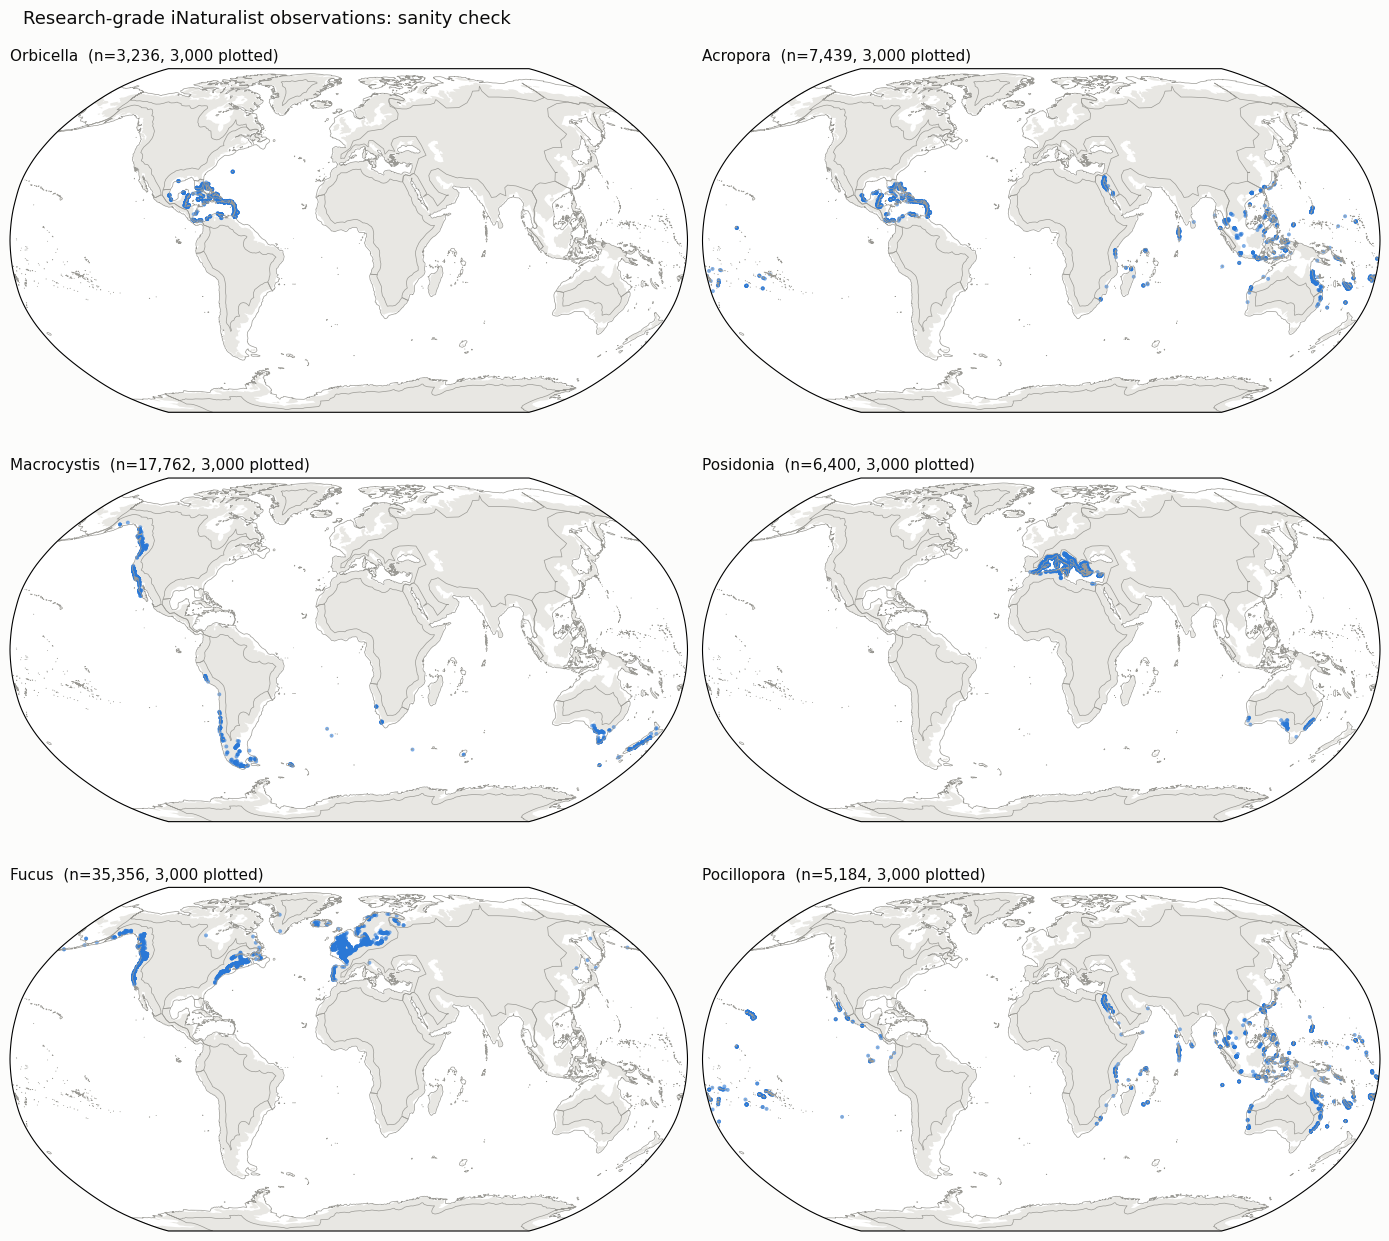

In [10]:
meow_all = gpd.read_file(MEOW_SHP)
meow = meow_all[meow_all.TYPE == "MEOW"].reset_index(drop=True)[["ECOREGION", "PROVINC", "REALM", "geometry"]]
REALMS = sorted(meow.REALM.unique())
realm_outline = meow.dissolve("REALM").geometry.simplify(0.1)
print(len(meow), "ecoregions,", meow.PROVINC.nunique(), "provinces,", len(REALMS), "realms")

SANITY = ["orbicella", "acropora", "macrocystis", "posidonia", "fucus", "pocillopora"]
fig, axes = plt.subplots(3, 2, figsize=(14, 13), subplot_kw={"projection": ccrs.Robinson()})
fig.patch.set_facecolor(SURFACE)
rng = np.random.default_rng(0)
for ax, g in zip(axes.flat, SANITY):
    d = obs[obs.genus == g]
    s = d.sample(min(len(d), 3000), random_state=0)
    ax.set_global()
    ax.add_feature(cfeature.LAND, facecolor="#e8e7e3", edgecolor="none")
    ax.add_geometries(realm_outline.values, crs=ccrs.PlateCarree(), facecolor="none",
                      edgecolor="#9a9994", linewidth=0.5)
    ax.scatter(s.lon, s.lat, s=8, color=C_BLUE, alpha=0.6, edgecolor="none", transform=ccrs.PlateCarree())
    ax.set_title(f"{g.capitalize()}  (n={len(d):,}, {len(s):,} plotted)", color=INK, fontsize=11, loc="left")
fig.suptitle("Research-grade iNaturalist observations: sanity check", color=INK, fontsize=13, x=0.02, ha="left")
plt.tight_layout()
fig.savefig(OUT / "sanity_map.png", dpi=150, facecolor=SURFACE)
plt.show()

## 6. Assign observations to MEOW ecoregion → province → realm

1. Point-in-polygon on the MEOW *NoCoast* layer. Its polygons already extend somewhat inland, so most shore
   observations fall inside.
2. For points still unmatched, find the nearest ecoregion and compute the **geodesic** distance to it. Keep the
   point if the distance is ≤ `SNAP_KM`.
3. Points that are still unassigned are dropped. These are open-ocean observations (pelagic, not covered by MEOW)
   or inland mislocations.

The assignment runs on unique coordinates and is cached in `data/coord_regions.parquet`.

In [11]:
COORD_CACHE = DATA / "coord_regions.parquet"
coords = obs[["lon", "lat"]].drop_duplicates().reset_index(drop=True)
cache = pd.read_parquet(COORD_CACHE) if COORD_CACHE.exists() else pd.DataFrame(columns=["lon", "lat"])
new = coords.merge(cache[["lon", "lat"]], how="left", indicator=True).query("_merge == 'left_only'")[["lon", "lat"]]
print(f"{len(coords):,} unique coords, {len(new):,} new to assign")

if len(new):
    pts = gpd.GeoDataFrame(new.reset_index(drop=True),
                           geometry=gpd.points_from_xy(new.lon, new.lat), crs=4326)
    inside = gpd.sjoin(pts, meow, how="left", predicate="within")
    inside = inside[~inside.index.duplicated(keep="first")]
    res = inside[["lon", "lat", "ECOREGION", "PROVINC", "REALM"]].copy()
    res["dist_km"] = np.where(res.REALM.notna(), 0.0, np.nan)

    miss = pts.loc[res.REALM.isna()]
    if len(miss):
        meow_s = meow.copy()
        meow_s["geometry"] = meow_s.geometry.simplify(0.005)   # ~0.5 km tolerance, speeds up nearest search
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")  # geographic-CRS warning: degrees are only used to pick the candidate
            near = gpd.sjoin_nearest(miss, meow_s, how="left", max_distance=2.0)
        near = near[~near.index.duplicated(keep="first")].dropna(subset=["REALM"])
        geod = Geod(ellps="WGS84")
        polys = meow_s.geometry
        d_km = []
        for pt, ix in tqdm(zip(near.geometry, near.index_right.astype(int)), total=len(near), desc="snap"):
            q = nearest_points(pt, polys.iloc[ix])[1]
            d_km.append(geod.inv(pt.x, pt.y, q.x, q.y)[2] / 1000)
        near["dist_km"] = d_km
        near = near[near.dist_km <= SNAP_KM]
        res.loc[near.index, ["ECOREGION", "PROVINC", "REALM", "dist_km"]] = \
            near[["ECOREGION", "PROVINC", "REALM", "dist_km"]].values
    cache = pd.concat([cache, res], ignore_index=True)
    cache.to_parquet(COORD_CACHE, index=False)

obs_r = obs.merge(cache, on=["lon", "lat"], how="left")
obs_r["region_assign"] = np.select([obs_r.dist_km == 0, obs_r.dist_km > 0], ["inside", f"snapped ≤{SNAP_KM} km"],
                            "unassigned")
print(obs_r.region_assign.value_counts(normalize=True).round(4))
obs_r.to_parquet(OUT / "observations_with_regions.parquet", index=False)

450,653 unique coords, 0 new to assign


region_assign
inside            0.9832
snapped ≤50 km    0.0153
unassigned        0.0015
Name: proportion, dtype: float64


Check: where did the snapped and unassigned points end up? Shown here for one genus with a wide range.

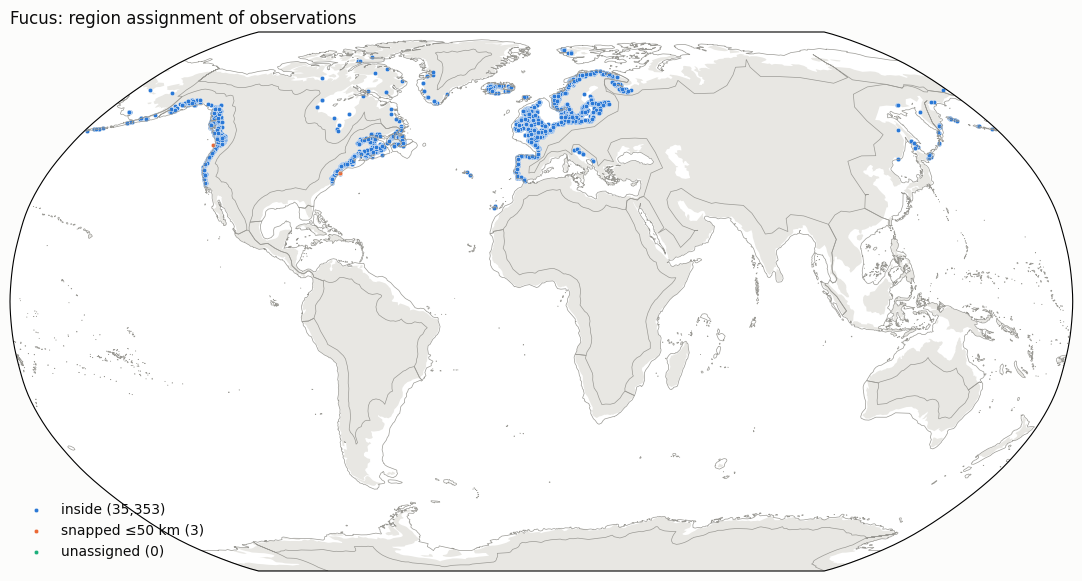

Unassigned share per genus (top 15):


genus
verrucaria       0.269
acanthogorgia    0.167
mytilaster       0.117
cladophora       0.099
ruppia           0.075
lyngbya          0.047
litophyton       0.041
ellisella        0.037
epizoanthus      0.016
rumphella        0.015
cantharellus     0.014
geodia           0.014
pachyrhynchia    0.014
junceella        0.013
blastomussa      0.013
Name: region_assign, dtype: float64

In [12]:
g = "fucus"
d = obs_r[obs_r.genus == g]
fig, ax = plt.subplots(figsize=(14, 7), subplot_kw={"projection": ccrs.Robinson()})
fig.patch.set_facecolor(SURFACE)
ax.set_global()
ax.add_feature(cfeature.LAND, facecolor="#e8e7e3", edgecolor="none")
ax.add_geometries(realm_outline.values, crs=ccrs.PlateCarree(), facecolor="none", edgecolor="#9a9994", linewidth=0.5)
for lab, col in zip(["inside", f"snapped ≤{SNAP_KM} km", "unassigned"], [C_BLUE, C_ORANGE, C_AQUA]):
    s = d[d.region_assign == lab]
    ax.scatter(s.lon, s.lat, s=10, color=col, edgecolor=SURFACE, linewidth=0.3,
               transform=ccrs.PlateCarree(), label=f"{lab} ({len(s):,})")
ax.legend(loc="lower left", frameon=False, labelcolor=INK)
ax.set_title(f"{g.capitalize()}: region assignment of observations", loc="left", color=INK)
plt.show()

print("Unassigned share per genus (top 15):")
unassigned_share = obs_r.groupby("genus")["region_assign"].apply(lambda s: (s == "unassigned").mean())
unassigned_share.sort_values(ascending=False).head(15).round(3)

## 7. Genus × realm matrix

`counts[g, r]` is the number of research-grade observations of genus *g* assigned to realm *r*.
`presence = counts ≥ MIN_OBS`. All CSV genera are rows, including those with zero iNat observations
(their rows are all False and they are flagged in `genus_inat_summary.csv`).

In [13]:
all_genera = sorted(genera.genus)
assigned = obs_r[obs_r.REALM.notna()]

counts = (pd.crosstab(assigned.genus, assigned.REALM)
            .reindex(index=all_genera, columns=REALMS, fill_value=0).astype(int))
presence = counts >= MIN_OBS
counts.index.name = presence.index.name = "genus"

counts.to_csv(OUT / "genus_realm_counts.csv")
presence.to_csv(OUT / "genus_realm_presence.csv")

# finer levels saved too (long format, counts) for later use
for lvl in ["PROVINC", "ECOREGION"]:
    (assigned.groupby(["genus", "REALM", lvl]).size().rename("n_obs").reset_index()
        .to_csv(OUT / f"genus_{lvl.lower()}_counts_long.csv", index=False))

summary = (taxa.set_index("genus")[["inat_id", "inat_name", "inat_phylum", "status", "shares_inat_taxon_with", "n_rg"]]
           .join(obs_r.groupby("genus").size().rename("n_with_coords"))
           .join(assigned.groupby("genus").size().rename("n_assigned"))
           .join(presence.sum(1).rename("n_realms"))
           .reindex(all_genera))
summary[["n_with_coords", "n_assigned"]] = summary[["n_with_coords", "n_assigned"]].fillna(0).astype(int)
summary.to_csv(OUT / "genus_inat_summary.csv")

print("matrix shape (N genera × M realms):", presence.shape)
print("genera with no assigned observations:", summary.index[summary.n_assigned == 0].tolist())
presence.head(20)

matrix shape (N genera × M realms): (366, 12)
genera with no assigned observations: ['abyla', 'boninastrea', 'cespitularia', 'craterastrea', 'ctenella', 'diaseris', 'hydnophyllia', 'indophyllia', 'montigyra', 'physophyllia', 'ramicrusta', 'rhipilia', 'schizothrix', 'simplastrea']


REALM,Arctic,Central Indo-Pacific,Eastern Indo-Pacific,Southern Ocean,Temperate Australasia,Temperate Northern Atlantic,Temperate Northern Pacific,Temperate South America,Temperate Southern Africa,Tropical Atlantic,Tropical Eastern Pacific,Western Indo-Pacific
genus,,,,,,,,,,,,
aaptos,False,True,False,False,True,True,True,False,False,False,False,True
abyla,False,False,False,False,False,False,False,False,False,False,False,False
acanthaster,False,True,True,False,True,False,True,False,True,False,True,True
acanthastrea,False,True,True,False,True,False,False,False,False,False,False,True
acanthogorgia,False,True,False,False,False,True,False,False,False,False,False,True
acanthophora,False,True,True,False,True,True,True,True,False,True,True,True
acanthophyllia,False,True,False,False,False,False,False,False,False,False,False,False
acetabularia,False,True,False,False,True,True,False,True,False,True,False,True
acropora,False,True,True,False,True,False,True,False,False,True,False,True


In [14]:
print("Number of genera present per realm:")
presence.sum().sort_values(ascending=False)

Number of genera present per realm:


REALM
Central Indo-Pacific           246
Western Indo-Pacific           220
Temperate Australasia          172
Temperate Northern Pacific     169
Eastern Indo-Pacific           165
Tropical Atlantic              161
Temperate Northern Atlantic    146
Temperate Southern Africa       94
Temperate South America         75
Tropical Eastern Pacific        66
Arctic                          17
Southern Ocean                   8
dtype: int64

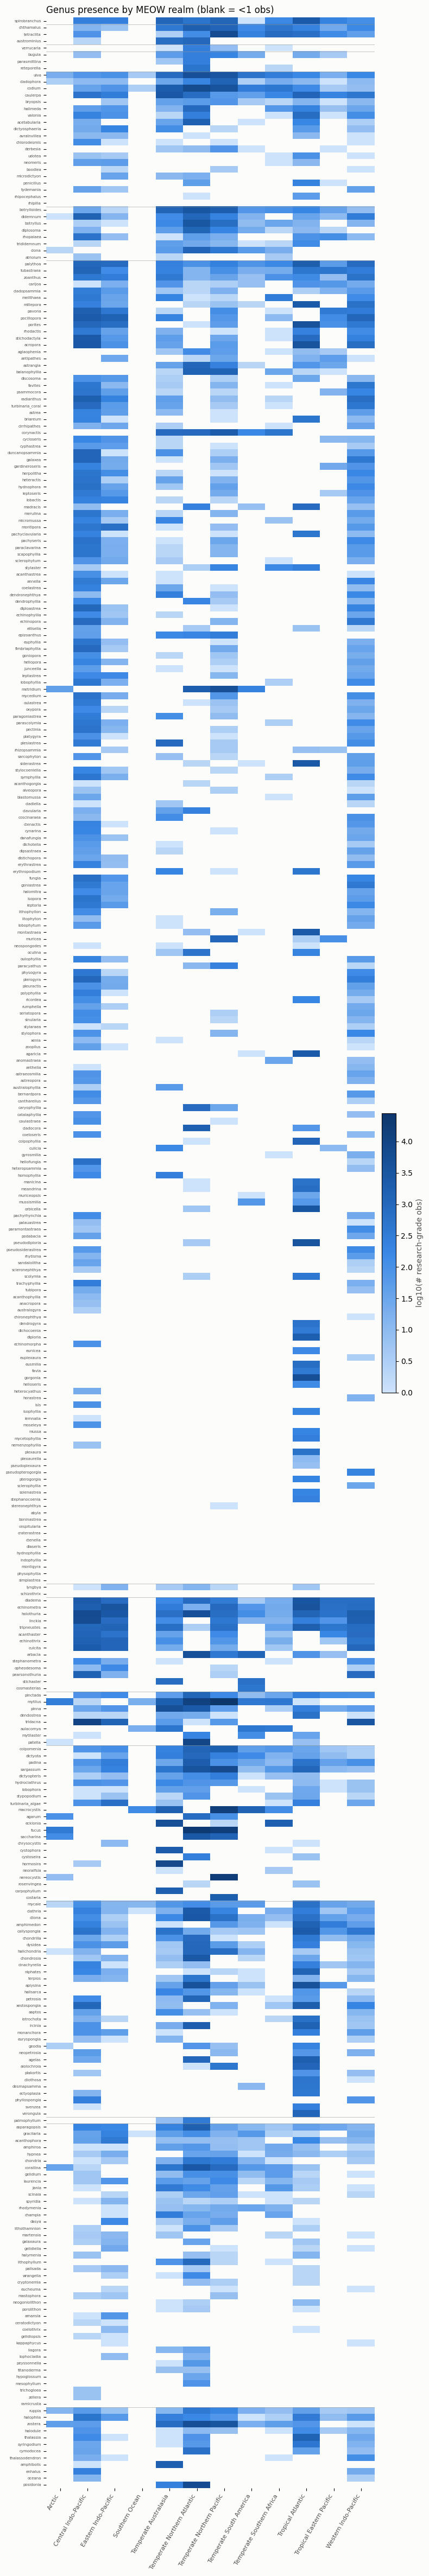

In [15]:
# heatmap: rows grouped by phylum then by number of realms; cells = log10(count), blank where absent
ph = taxa.set_index("genus").csv_phylum.reindex(all_genera)
order = (pd.DataFrame({"ph": ph, "n": presence.sum(1)}).sort_values(["ph", "n"], ascending=[True, False]).index)
M = np.log10(counts.loc[order].where(presence.loc[order]).astype(float))

from matplotlib.colors import LinearSegmentedColormap
seq = LinearSegmentedColormap.from_list("seqblue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
fig, ax = plt.subplots(figsize=(8, max(10, len(order) * 0.13)))
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)
im = ax.imshow(M.values, aspect="auto", cmap=seq, interpolation="nearest")
ax.set_xticks(range(len(REALMS))); ax.set_xticklabels(REALMS, rotation=60, ha="right", fontsize=8, color=INK2)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=5, color=INK2)
# phylum separators
bounds = np.flatnonzero(ph.loc[order].values[1:] != ph.loc[order].values[:-1]) + 0.5
for b in bounds: ax.axhline(b, color="#9a9994", lw=0.4)
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.set_label("log10(# research-grade obs)", color=INK2)
ax.set_title(f"Genus presence by MEOW realm (blank = <{MIN_OBS} obs)", loc="left", color=INK)
plt.tight_layout(); fig.savefig(OUT / "genus_realm_heatmap.png", dpi=200, facecolor=SURFACE); plt.show()

## 8. Genus richness per MEOW region

Richness is the number of genera with ≥ `MIN_OBS` research-grade observations in a region. Columns are the 12
**realms** (the same presence matrix as above) and the 232 **ecoregions** (from `genus_ecoregion_counts_long.csv`).
The top row counts all genera in the CSV. The bottom row counts only scleractinian (hard coral) genera, the set
the geographic gating in `Genus_Geographic_Gating.ipynb` uses.

Ecoregion richness also tracks how much iNat sampling an ecoregion gets. For example, densely dived coasts such as
Florida, Hawaiʻi and the Red Sea score high partly for that reason, so read the ecoregion panels as observed
richness, not true richness.

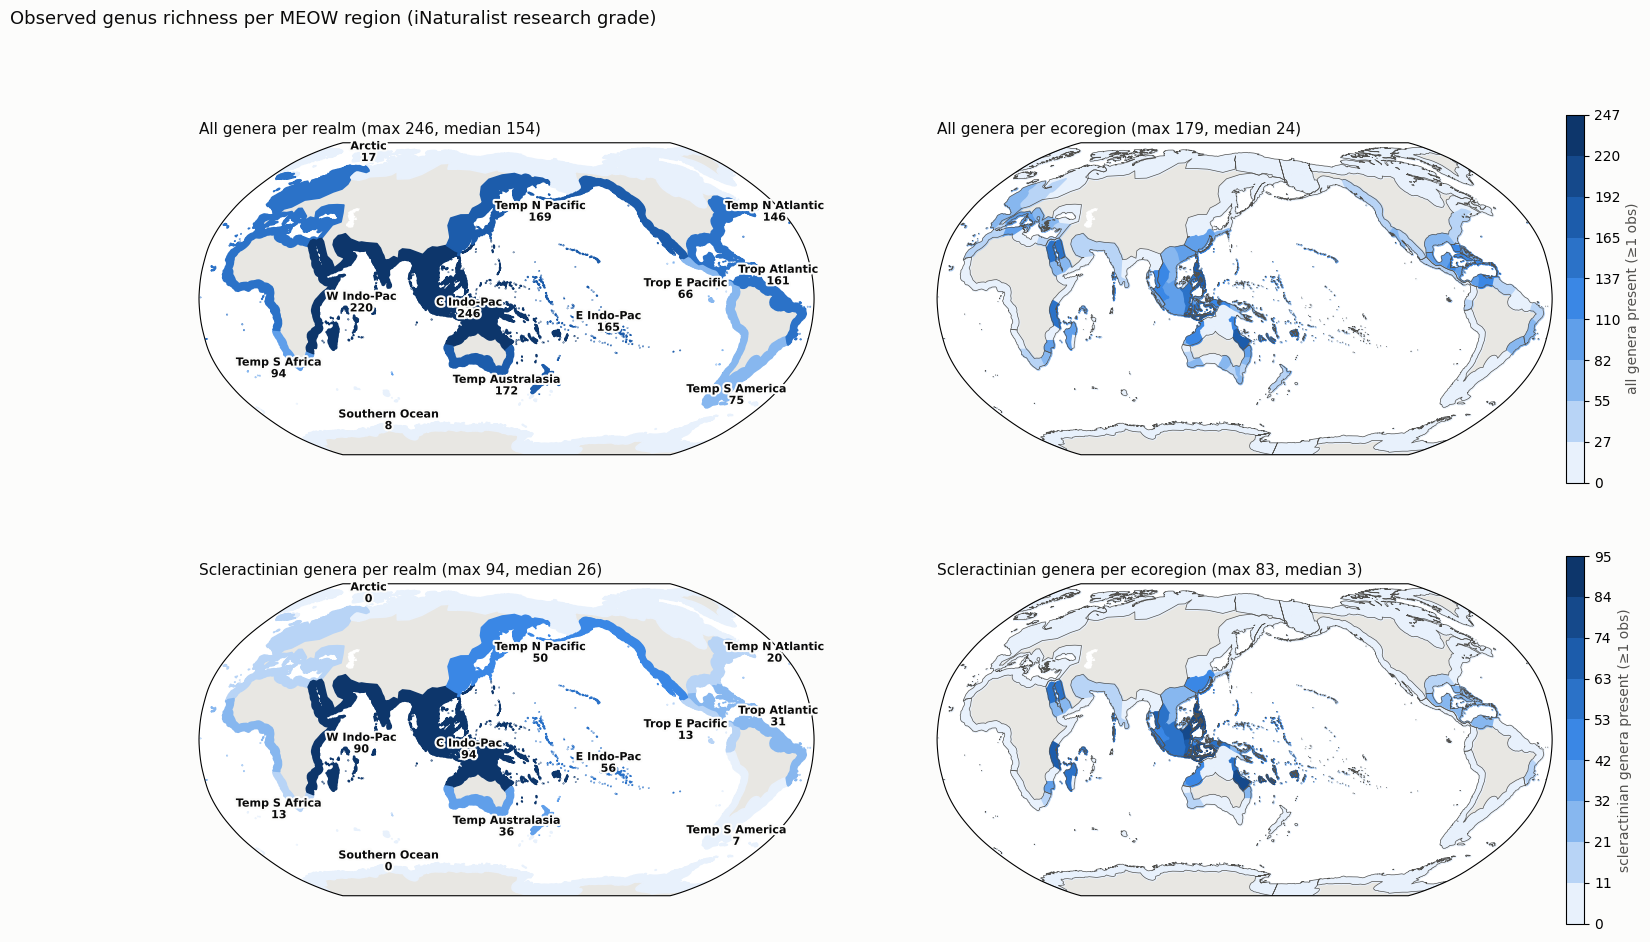

Top 10 ecoregions by scleractinian genus richness:
ECOREGION
Lesser Sunda                               83
New Caledonia                              78
Central and Southern Great Barrier Reef    77
Palawan/North Borneo                       77
Banda Sea                                  74
Eastern Philippines                        74
Sulawesi Sea/Makassar Strait               71
East African Coral Coast                   68
Fiji Islands                               68
Andaman Sea Coral Coast                    65


,all genera,scleractinian genera
REALM,,
Central Indo-Pacific,246,94
Western Indo-Pacific,220,90
Temperate Australasia,172,36
Temperate Northern Pacific,169,50
Eastern Indo-Pacific,165,56
Tropical Atlantic,161,31
Temperate Northern Atlantic,146,20
Temperate Southern Africa,94,13
Temperate South America,75,7


In [16]:
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
import matplotlib.patheffects as pe

# Fixed label positions (lon, lat) so realm numbers sit over open water and don't collide.
REALM_LABEL_AT = {
    "Arctic": (20, 80), "Central Indo-Pacific": (128, -5), "Eastern Indo-Pacific": (-150, -12),
    "Southern Ocean": (60, -64), "Temperate Australasia": (150, -45), "Temperate Northern Atlantic": (-35, 45),
    "Temperate Northern Pacific": (172, 45), "Temperate South America": (-55, -50),
    "Temperate Southern Africa": (8, -36), "Tropical Atlantic": (-50, 12), "Tropical Eastern Pacific": (-105, 5),
    "Western Indo-Pacific": (65, -2),
}
SHORT = {"Central Indo-Pacific": "C Indo-Pac", "Eastern Indo-Pacific": "E Indo-Pac", "Western Indo-Pacific": "W Indo-Pac",
         "Temperate Australasia": "Temp Australasia", "Temperate Northern Atlantic": "Temp N Atlantic",
         "Temperate Northern Pacific": "Temp N Pacific", "Temperate South America": "Temp S America",
         "Temperate Southern Africa": "Temp S Africa", "Tropical Atlantic": "Trop Atlantic",
         "Tropical Eastern Pacific": "Trop E Pacific", "Southern Ocean": "Southern Ocean", "Arctic": "Arctic"}
HALO = [pe.withStroke(linewidth=3, foreground=SURFACE)]

scler_genera = sorted(set(c2c.loc[c2c.order.str.lower() == "scleractinia", "genus"].dropna()) - {"none", "not_given"})
eco_long = pd.read_csv(OUT / "genus_ecoregion_counts_long.csv")
eco_pres = eco_long[eco_long.n_obs >= MIN_OBS]
GROUPS = {"all genera": all_genera, "scleractinian genera": scler_genera}

rich = {}
for name, gs in GROUPS.items():
    rich[(name, "realm")] = presence.loc[gs].sum().reindex(REALMS)
    rich[(name, "ecoregion")] = (eco_pres[eco_pres.genus.isin(gs)].groupby("ECOREGION").genus.nunique()
                                 .reindex(meow.ECOREGION, fill_value=0))

meow_plot = meow.copy()
meow_plot["geometry"] = meow_plot.geometry.simplify(0.05)
realm_poly = meow_plot.dissolve("REALM").reindex(REALMS)
seq = LinearSegmentedColormap.from_list("seqblue", ["#e8f1fc", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

fig, axes = plt.subplots(2, 2, figsize=(18, 10.5), subplot_kw={"projection": ccrs.Robinson(central_longitude=150)})
fig.patch.set_facecolor(SURFACE)
for i, name in enumerate(GROUPS):
    vmax = int(max(rich[(name, "realm")].max(), rich[(name, "ecoregion")].max()))
    bounds = np.unique(np.linspace(0, vmax + 1, 10).round())
    norm = BoundaryNorm(bounds, seq.N)
    for j, lvl in enumerate(("realm", "ecoregion")):
        ax = axes[i, j]
        ax.set_global()
        ax.add_feature(cfeature.LAND, facecolor="#e8e7e3", edgecolor="none", zorder=0)
        r = rich[(name, lvl)]
        gdf = realm_poly.assign(rich=r.values) if lvl == "realm" else meow_plot.assign(rich=r.values)
        for geom, v in zip(gdf.geometry, gdf.rich):
            # edge in the fill colour so small island ecoregions (e.g. the Eastern Indo-Pacific) stay visible
            ax.add_geometries([geom], crs=ccrs.PlateCarree(), facecolor=seq(norm(v)), edgecolor=seq(norm(v)),
                              linewidth=1.2)
        if lvl == "realm":
            for realm, (lon, lat) in REALM_LABEL_AT.items():
                ax.text(lon, lat, f"{SHORT[realm]}\n{int(r[realm])}", transform=ccrs.PlateCarree(), ha="center",
                        va="center", fontsize=8, color=INK, fontweight="bold", path_effects=HALO)
        else:
            ax.add_geometries(realm_outline.values, crs=ccrs.PlateCarree(), facecolor="none",
                              edgecolor=INK2, linewidth=0.5)
        ax.set_title(f"{name.capitalize()} per {lvl} (max {int(r.max())}, median {r.median():.0f})",
                     loc="left", color=INK, fontsize=11)
    cb = fig.colorbar(ScalarMappable(norm=norm, cmap=seq), ax=axes[i].tolist(), fraction=0.02, pad=0.01)
    cb.set_label(f"{name} present (≥{MIN_OBS} obs)", color=INK2)
fig.suptitle("Observed genus richness per MEOW region (iNaturalist research grade)", color=INK, fontsize=13,
             x=0.02, ha="left")
fig.savefig(OUT / "genus_richness_map.png", dpi=150, facecolor=SURFACE, bbox_inches="tight")
plt.show()

rich_realm = pd.DataFrame({name: rich[(name, "realm")] for name in GROUPS}).sort_values("all genera", ascending=False)
rich_realm.to_csv(OUT / "genus_richness_realm.csv")
pd.DataFrame({name: rich[(name, "ecoregion")].values for name in GROUPS},
             index=pd.MultiIndex.from_frame(meow[["REALM", "PROVINC", "ECOREGION"]])).to_csv(
    OUT / "genus_richness_ecoregion.csv")
print("Top 10 ecoregions by scleractinian genus richness:")
print(rich[("scleractinian genera", "ecoregion")].sort_values(ascending=False).head(10).to_string())
rich_realm

## 9. Adding presences from our own annotations (CoralNet train + val)

A genus × realm cell becomes True if **iNat has ≥ `MIN_OBS` research-grade observations** of the genus in the realm
(as above), **or a CoralNet train or val source in that realm has ≥ `MIN_ANN_PTS` annotated point(s) of it**.

- **Sources.** Train and val splits only (`configs/coralnet/source_splits.csv`), so the test labels never enter
  the matrix and the gating evaluation stays clean. Sources missing from the split file have an unknown split and
  are left out.
- **Genus of a label.** The `coralnet` rows of `configs/class_to_concepts.csv`. Labels without a genus (`none`,
  `not_given`) don't count.
- **Realm of a source.** Its scraped CoralNet coordinate, placed in a MEOW ecoregion by point-in-polygon, or snapped
  to the nearest one within `SRC_SNAP_KM`. The snap is wider than for iNat because about a quarter of the coordinates
  are rounded to whole degrees.
- **Dropping sources with wrong coordinates.** Scraped coordinates contain sign errors. For example, the Veracruz
  reefs at longitude +96 instead of −96 land in the Bay of Bengal, and would add Atlantic genera to the Western
  Indo-Pacific. A source is dropped if:
  1. it has ≥ `MIN_SCLER_PTS` hard coral genus points and fewer than `MIN_FIT` of them are genera iNat records in its
     coordinate realm, or
  2. flipping the sign of its longitude, latitude or both lands it in a realm that fits its annotations at least
     `FLIP_MARGIN` better.

  Hard coral genera decide the fit when there are enough of them: iNat covers them well, and the Atlantic and
  Indo-Pacific genera barely overlap. Otherwise all genera are used, but only for rule 2 and only with ≥ 3 genera,
  because iNat covers many algae poorly (e.g. *Peyssonnelia*).

In [17]:
import sys
SRC_SNAP_KM = 100     # sources: snap to the nearest ecoregion within this distance
MIN_ANN_PTS = 1       # annotated points of a genus in one source to count as present in its realm
MIN_SCLER_PTS = 20    # hard coral genus points needed to judge a source on hard corals
MIN_FIT, FLIP_MARGIN, MIN_GENERA_ALL = 0.8, 0.05, 3
SPLITS_CSV = ROOT / "configs/coralnet/source_splits.csv"
ANN_CACHE = DATA / "coralnet_source_label_counts.parquet"

# Points per (source, CoralNet label) for every source in the training manifest; cached (needs S3 access once).
if ANN_CACHE.exists():
    src_lab = pd.read_parquet(ANN_CACHE)
else:
    import yaml
    sys.path.insert(0, str(ROOT))
    from mermaidseg.datasets.local_cache import LocalS3Cache, setup_local_cache
    from mermaidseg.datasets.coralnet import coralnet_dataset as cnd
    cfg = yaml.safe_load((ROOT / "configs/data_config_dedup.yaml").read_text())
    setup_local_cache(cfg.get("data", cfg))
    man = LocalS3Cache.get().read_parquet("dev-datamermaid-sm-sources", cnd._resolve_default_manifest_path())
    id2 = LocalS3Cache.get().read_json("dev-datamermaid-sm-sources", cnd._CORALNET_ID2NAME_KEY)
    man["label"] = man.coralnet_id.map(lambda x: id2.get(str(x))).astype(str).str.lower()
    src_lab = man.groupby(["source_id", "label"]).size().rename("n").reset_index()
    src_lab.to_parquet(ANN_CACHE, index=False)
    del man

lab2 = c2c[c2c.source_dataset_source.str.lower() == "coralnet"].assign(
    label=lambda d: d.source_label_class_name.str.lower(), genus=lambda d: d.genus.str.lower(),
    order=lambda d: d.order.str.lower()).drop_duplicates("label")[["label", "genus", "order"]]
src_gen = src_lab.merge(lab2, on="label", how="left")
print(f"{src_lab.source_id.nunique()} sources in the manifest; {src_gen.genus.notna().mean():.1%} of (source, label) "
      f"rows map to a concept row")
src_gen = (src_gen[src_gen.genus.isin(all_genera)]
           .groupby(["source_id", "genus", "order"], as_index=False).n.sum())

splits = pd.read_csv(SPLITS_CSV)
tv = splits[splits.split.isin(["train", "val"])].dropna(subset=["latitude", "longitude"]).reset_index(drop=True)
print(f"train + val sources: {splits.split.isin(['train', 'val']).sum()}, with coordinates {len(tv)}, "
      f"with genus annotations {tv.source_id.isin(src_gen.source_id).sum()}")

1294 sources in the manifest; 85.6% of (source, label) rows map to a concept row
train + val sources: 682, with coordinates 614, with genus annotations 501


In [18]:
geod = Geod(ellps="WGS84")


def realm_of(lon, lat, max_km=SRC_SNAP_KM):
    # MEOW realm of each coordinate: inside a polygon, else nearest ecoregion within max_km (else None)
    g = gpd.GeoDataFrame(geometry=gpd.points_from_xy(lon, lat), crs=4326)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # degrees only pick the candidate polygon; distance is geodesic below
        j = gpd.sjoin_nearest(g, meow[["REALM", "geometry"]], how="left", max_distance=3.0)
    j = j[~j.index.duplicated()]
    out = []
    for pt, ix, realm in zip(j.geometry, j.index_right, j.REALM):
        if pd.isna(ix):
            out.append(None)
            continue
        poly = meow.geometry.iloc[int(ix)]
        if poly.contains(pt):
            out.append(realm)
            continue
        q = nearest_points(pt, poly)[1]
        out.append(realm if geod.inv(pt.x, pt.y, q.x, q.y)[2] / 1000 <= max_km else None)
    return out


tv["REALM"] = realm_of(tv.longitude, tv.latitude)
FLIPS = {"flip lon": (-1, 1), "flip lat": (1, -1), "flip both": (-1, -1)}
for k, (sx, sy) in FLIPS.items():
    tv[k] = realm_of(tv.longitude * sx, tv.latitude * sy)

inat_has = counts >= 1                                  # fit is judged against iNat (any record)
judgeable = counts.sum(axis=1) > 0                      # genera iNat has no data on can't be judged
sg = src_gen[src_gen.genus.map(judgeable)]


def fit(sid, realm, scler):
    x = sg[(sg.source_id == sid) & ((sg.order == "scleractinia") if scler else True)].groupby("genus").n.sum()
    if realm is None or x.sum() == 0:
        return np.nan, 0
    return float((inat_has.loc[x.index, realm] * x).sum() / x.sum()), len(x)


rows = []
for r in tv.itertuples():
    n_scl = int(sg[(sg.source_id == r.source_id) & (sg.order == "scleractinia")].n.sum())
    scler = n_scl >= MIN_SCLER_PTS
    own, n_gen = fit(r.source_id, r.REALM, scler)
    reasons = []
    if r.REALM is None:
        reasons.append("no MEOW realm within snap distance")
    elif not np.isnan(own) and (scler or n_gen >= MIN_GENERA_ALL):
        if scler and own < MIN_FIT:
            reasons.append(f"hard coral fit {own:.2f} < {MIN_FIT}")
        for k in FLIPS:
            fr = tv.at[r.Index, k]
            if fr and fr != r.REALM:
                f, _ = fit(r.source_id, fr, scler)
                if f - own >= FLIP_MARGIN:
                    reasons.append(f"{k} → {fr} fits {f:.2f} vs {own:.2f}")
    rows.append({"source_id": r.source_id, "hard coral genus pts": n_scl,
                 "judged on": "hard corals" if scler else "all genera", "fit in realm": own,
                 "drop reason": "; ".join(reasons)})
SRC_CHECK = tv[["source_id", "name", "split", "latitude", "longitude", "REALM"]].merge(pd.DataFrame(rows), on="source_id")
SRC_CHECK["used"] = SRC_CHECK["drop reason"] == ""
SRC_CHECK.to_csv(OUT / "coralnet_source_realm_check.csv", index=False)

has_ann = SRC_CHECK.source_id.isin(src_gen.source_id)
print(f"{has_ann.sum()} train + val sources with coordinates and genus annotations: "
      f"{(SRC_CHECK.used & has_ann).sum()} used, {(~SRC_CHECK.used & has_ann).sum()} dropped")
print(SRC_CHECK[has_ann].assign(status=lambda d: np.where(d.used, "used", "dropped"))
      .pivot_table(index="REALM", columns="status", values="source_id", aggfunc="count", fill_value=0))
dropped = SRC_CHECK[~SRC_CHECK.used & has_ann & SRC_CHECK.REALM.notna()]
dropped[["source_id", "name", "latitude", "longitude", "REALM", "judged on", "drop reason"]].sort_values("REALM")

501 train + val sources with coordinates and genus annotations: 352 used, 149 dropped
status                       dropped  used
REALM                                     
Arctic                             0     1
Central Indo-Pacific               0    71
Eastern Indo-Pacific               0    86
Temperate Australasia              0    11
Temperate Northern Atlantic        2    33
Temperate Northern Pacific         0    14
Temperate South America            0     5
Tropical Atlantic                  0    77
Tropical Eastern Pacific           0     3
Western Indo-Pacific              80    51


,source_id,name,latitude,longitude,REALM,judged on,drop reason
429,3004,BIOL 4950,27.71278,-97.3253,Temperate Northern Atlantic,hard corals,hard coral fit 0.58 < 0.8
102,2297,CoralNet_Assistance_Test_0921,32.00000,32.0000,Temperate Northern Atlantic,hard corals,hard coral fit 0.51 < 0.8
0,4915,Blanca,19.00000,96.0000,Western Indo-Pacific,hard corals,flip lon → Tropical Atlantic fits 1.00 vs 0.89
73,6540,SantiaguilloSEPT2024,19.00000,95.0000,Western Indo-Pacific,hard corals,hard coral fit 0.40 < 0.8; flip lon → Tropical...
69,6363,Blanqueamiento 2024_Nov-Dic,18.00000,95.0000,Western Indo-Pacific,hard corals,hard coral fit 0.09 < 0.8; flip lon → Tropical...
...,...,...,...,...,...,...,...
24,5393,Blanquilla T1S_MFV,19.00000,96.0000,Western Indo-Pacific,hard corals,hard coral fit 0.05 < 0.8; flip lon → Tropical...
23,5104,T8s,19.00000,96.0000,Western Indo-Pacific,hard corals,hard coral fit 0.43 < 0.8; flip lon → Tropical...
22,5073,T7s,19.00000,96.0000,Western Indo-Pacific,hard corals,hard coral fit 0.21 < 0.8; flip lon → Tropical...
20,5068,T3S,19.00000,96.0000,Western Indo-Pacific,hard corals,hard coral fit 0.02 < 0.8; flip lon → Tropical...


Sources that fit their realm least well among those **kept** (hard coral fit < 1). Most are genuine sources near a
realm boundary, such as Taiwan, Moreton Bay and Samoa, where iNat lacks a few genera on one side.

In [19]:
SRC_CHECK[SRC_CHECK.used & has_ann & (SRC_CHECK["fit in realm"] < 1)].sort_values("fit in realm").head(20)[
    ["source_id", "name", "latitude", "longitude", "REALM", "judged on", "hard coral genus pts", "fit in realm"]]

,source_id,name,latitude,longitude,REALM,judged on,hard coral genus pts,fit in realm
240,1895,MBON,-42.700000,-64.96000,Temperate South America,all genera,0,0.000000
493,7132,"23/25 CAUs Gayana Resort, Sabah, Malaysia",6.013520,114.04820,Central Indo-Pacific,all genera,0,0.000000
446,3922,Pangatalan SRP,11.087340,119.56340,Central Indo-Pacific,all genera,0,0.059252
461,5444,Tubbataha,8.874217,119.88560,Central Indo-Pacific,all genera,0,0.242737
600,6207,fire coral settlement tiles - Curaçao,12.085270,-68.89810,Tropical Atlantic,all genera,11,0.304136
470,5774,Sharkplaneos Artificial Reef,18.479950,-64.45600,Tropical Atlantic,all genera,10,0.476190
362,3379,NTOU SSlab MO investigate,25.018090,121.98930,Temperate Northern Pacific,hard corals,776,0.885309
262,843,Okinawa Coral Reef Conservation2017-18,26.500000,127.85000,Central Indo-Pacific,hard corals,5658,0.887946
599,6068,Photo Analysis Sukuta Transect,26.555300,127.99170,Central Indo-Pacific,hard corals,460,0.923913
363,4250,Chao Jing Park Surveys 潮境公園調查,25.144540,121.80480,Temperate Northern Pacific,hard corals,16641,0.925666


### 9.1 Combined matrix

`ann_points[g, r]` is the number of annotated points of genus *g* in the used train and val sources of realm *r*, and
`ann_sources[g, r]` is the number of those sources with ≥ `MIN_ANN_PTS` points of it. The combined presence is
`counts ≥ MIN_OBS` **or** `ann_sources ≥ 1`. Saved as `genus_realm_presence_combined.csv`; the iNat-only matrix
`genus_realm_presence.csv` is unchanged.

In [20]:
used = SRC_CHECK.loc[SRC_CHECK.used, ["source_id", "REALM"]]
ann = src_gen.merge(used, on="source_id")
ann_points = (ann.pivot_table(index="genus", columns="REALM", values="n", aggfunc="sum", fill_value=0)
              .reindex(index=all_genera, columns=REALMS, fill_value=0).astype(int))
ann_sources = (ann[ann.n >= MIN_ANN_PTS].pivot_table(index="genus", columns="REALM", values="source_id",
                                                     aggfunc="nunique", fill_value=0)
               .reindex(index=all_genera, columns=REALMS, fill_value=0).astype(int))
presence_comb = presence | (ann_sources >= 1)
for df, name in ((ann_points, "annotation_points"), (ann_sources, "annotation_sources"),
                 (presence_comb, "presence_combined")):
    df.index.name = "genus"
    df.to_csv(OUT / f"genus_realm_{name}.csv")

added = presence_comb & ~presence
ann_only = ann_sources >= 1
summary_r = pd.DataFrame({
    "iNat": presence.sum(), "annotations": ann_only.sum(), "both": (presence & ann_only).sum(),
    "added by annotations": added.sum(), "combined": presence_comb.sum(),
    "used sources": used.REALM.value_counts().reindex(REALMS, fill_value=0)})
print(f"True cells: iNat {int(presence.values.sum())}, combined {int(presence_comb.values.sum())} "
      f"(+{int(added.values.sum())} from annotations); annotated cells already in iNat: "
      f"{int((presence & ann_only).values.sum())} of {int(ann_only.values.sum())}")
summary_r.sort_values("combined", ascending=False)

True cells: iNat 1539, combined 1613 (+74 from annotations); annotated cells already in iNat: 491 of 565


,iNat,annotations,both,added by annotations,combined,used sources
REALM,,,,,,
Central Indo-Pacific,246,110,97,13,259,92
Western Indo-Pacific,220,101,86,15,235,73
Eastern Indo-Pacific,165,93,74,19,184,96
Temperate Australasia,172,41,31,10,182,17
Temperate Northern Pacific,169,52,44,8,177,15
Tropical Atlantic,161,96,90,6,167,102
Temperate Northern Atlantic,146,52,51,1,147,44
Temperate Southern Africa,94,0,0,0,94,0
Temperate South America,75,14,13,1,76,8


The cells added by annotations, i.e. genus × realm pairs iNat has no research-grade record of. Each shows the
annotated points and the number of sources. Hard coral genera come first. Cells backed by a single source and few
points are the ones most likely to be label errors or outdated names (e.g. *Favia* in the Indo-Pacific, now
*Dipsastraea*).

In [21]:
ph = taxa.set_index("genus").csv_phylum.reindex(all_genera)
is_scler = pd.Series(all_genera, index=all_genera).isin(
    c2c.loc[c2c.order.str.lower() == "scleractinia", "genus"].str.lower())
add_long = (added.stack().loc[lambda s: s].reset_index().rename(columns={"level_1": "REALM"})
            [["genus", "REALM"]])
add_long["points"] = [ann_points.at[g, r] for g, r in zip(add_long.genus, add_long.REALM)]
add_long["sources"] = [ann_sources.at[g, r] for g, r in zip(add_long.genus, add_long.REALM)]
add_long["iNat obs worldwide"] = add_long.genus.map(counts.sum(axis=1))
add_long["hard coral"] = add_long.genus.map(is_scler)
add_long["phylum"] = add_long.genus.map(ph)
add_long = add_long.sort_values(["hard coral", "points"], ascending=[False, False]).reset_index(drop=True)
add_long.to_csv(OUT / "genus_realm_added_by_annotations.csv", index=False)
print(f"{len(add_long)} cells added ({int(add_long['hard coral'].sum())} hard coral); "
      f"backed by one source with < 10 points: {int(((add_long.sources == 1) & (add_long.points < 10)).sum())}")
add_long.head(40)

74 cells added (31 hard coral); backed by one source with < 10 points: 23


,genus,REALM,points,sources,iNat obs worldwide,hard coral,phylum
0,favia,Central Indo-Pacific,4602,17,351,True,cnidaria
1,astreopora,Eastern Indo-Pacific,3220,2,84,True,cnidaria
2,favia,Eastern Indo-Pacific,2524,3,351,True,cnidaria
3,dipsastraea,Temperate Northern Pacific,869,2,84,True,cnidaria
4,goniastrea,Temperate Australasia,830,1,772,True,cnidaria
5,coscinaraea,Eastern Indo-Pacific,339,2,220,True,cnidaria
6,favia,Western Indo-Pacific,319,3,351,True,cnidaria
7,favia,Temperate Australasia,307,1,351,True,cnidaria
8,montastraea,Central Indo-Pacific,285,14,2333,True,cnidaria
9,dipsastraea,Eastern Indo-Pacific,232,2,84,True,cnidaria


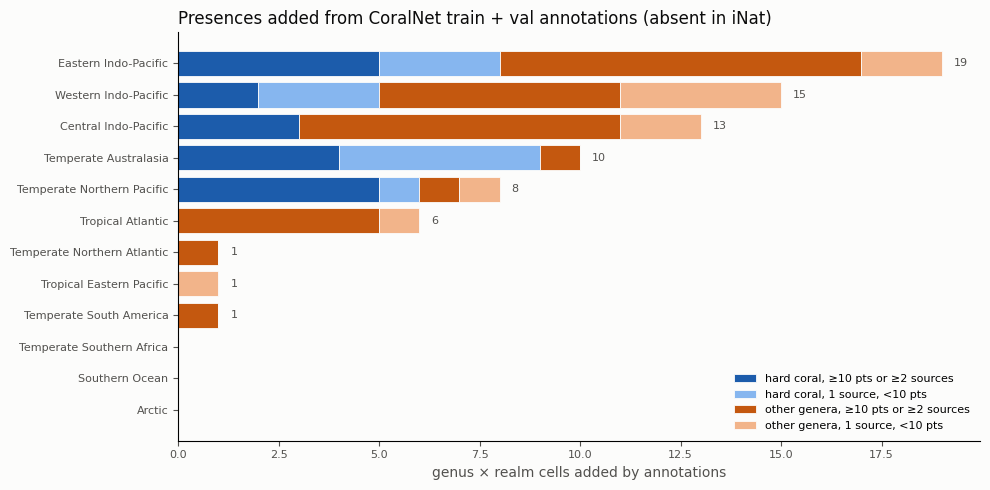

In [22]:
# Where the additions are: per realm, hard coral vs other genera, split by evidence strength.
strong = (add_long.points >= 10) | (add_long.sources >= 2)
tab = (add_long.assign(group=np.where(add_long["hard coral"], "hard coral", "other genera"),
                       evidence=np.where(strong, "≥10 pts or ≥2 sources", "1 source, <10 pts"))
       .pivot_table(index="REALM", columns=["group", "evidence"], values="genus", aggfunc="count", fill_value=0)
       .reindex(REALMS, fill_value=0))
order = tab.sum(axis=1).sort_values().index
fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)
left = np.zeros(len(order))
colors = {("hard coral", "≥10 pts or ≥2 sources"): "#1c5cab", ("hard coral", "1 source, <10 pts"): "#86b6ef",
          ("other genera", "≥10 pts or ≥2 sources"): "#c4580f", ("other genera", "1 source, <10 pts"): "#f2b48a"}
for col, colr in colors.items():
    if col in tab.columns:
        v = tab.loc[order, col].to_numpy()
        ax.barh(order, v, left=left, color=colr, label=f"{col[0]}, {col[1]}", edgecolor=SURFACE, lw=0.6)
        left += v
for y, v in enumerate(left):
    if v:
        ax.text(v + 0.3, y, f"{int(v)}", va="center", fontsize=8, color=INK2)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.tick_params(colors=INK2, labelsize=8)
ax.set_xlabel("genus × realm cells added by annotations", color=INK2)
ax.set_title("Presences added from CoralNet train + val annotations (absent in iNat)", loc="left", color=INK)
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
fig.savefig(OUT / "genus_realm_added_by_annotations.png", dpi=150, facecolor=SURFACE)
plt.show()